### 1-Library Compatibiliy
* Create a separate virtual environment for this project with `python==3.10`.
* These specific library versions are crucial for this project to run without errors. They will be installed via `%pip install` later:
  * `numpy==1.26.4`: `gym` and the `nes-py` NES emulator require this older NumPy version.
  * `gym==0.25.2`: this keeps the classic 4-tuple `.step()` API -> `(obs, reward, done, info)` and the observation only `reset()` API.
    * `gym >= 0.26` switches to a 5-tuple API that `nes-py` does not support, which would otherwise crash inside Gym's TimeLimit wrapper.
    * that's the error: `env.step` breaks with "not enough values to unpack (expected 5, got 4)".
  * `gym-super-mario-bros==7.4.0`
    * Even though `gym==0.25.2` supports `render_mode`, `gym-super-mario-bros==7.4.0` was built for an older version of OpenAI Gym (gym<=0.26.0) that does not accept `render_mode` inside the `make()` function.

### 2-Liabraries and dependences to install
* Install these in your Jupyter
```python
# Core Training Stack
%pip install torch==2.3.1
%pip install torchvision==0.18.1
%pip install numpy==1.26.4
%pip install opencv-python==4.10.0.84
%pip install matplotlib==3.8.4

# Mario Environment
%pip install gym==0.25.2
%pip install gym-super-mario-bros==7.4.0
%pip install nes-py==8.2.1

# Only needed if you have to play this game yourself
%pip install pygame
%pip install torchview
%pip install pandas==2.2.2
```
* Install these software dependencies on your PC
  ```text
  C++ Compiler
  Graphviz
  ```

---

**Update on Ubuntu with uv**

In Terminal
```bash
sudo apt update && sudo apt install build-essential python3-dev
```

In Jupyter Cell
```python
# Core Training Stack
!uv pip install torch==2.3.1
!uv pip install torchvision==0.18.1
!uv pip install numpy==1.26.4
!uv pip install opencv-python==4.10.0.84
!uv pip install matplotlib==3.8.4

# Mario Environment
!uv pip install gym==0.25.2
!uv pip install gym-super-mario-bros==7.4.0
!uv pip install nes-py==8.2.1
```

#### 2.0-Codemo to confirm your library versions

In [2]:
import pygame
print('pygame version is: ', pygame.__version__)
import numpy as np
print('numpy version is: ', np.__version__)
import gym
print('gym version is: ', gym.__version__)
import gym_super_mario_bros
import importlib.metadata
version = importlib.metadata.version('gym-super-mario-bros')
print('gym-super-mario-bros version is:', version)
import cv2
print('opencv-python version is:', cv2.__version__)
import matplotlib
print('matplotlib version is:', matplotlib.__version__)
import pandas
print('pandas version is: ', pandas.__version__)

pygame version is:  2.6.1
,,,,numpy version is:  1.26.4
,,,,gym version is:  0.25.2
,,,,gym-super-mario-bros version is: 7.4.0
,,,,opencv-python version is: 4.10.0
,,,,matplotlib version is: 3.8.4
,,,,pandas version is:  2.2.2


#### 2.1-Gameplay footage rendering Requirement
* C++ Compiler
  * use Microsoft’s Build Tools for Visual Studio to install the C++ compiler.
  * It is required to render and display the gameplay window graphically, on a monitor.
* `gym_super_mario_bros` library, this is the game
  * `nes-py` is just the simulator
* `pygame` library is required to visually project the game state onto your monitor.
  * So you can manually play the game on your computer.
  * We also need this so we can watch the AI play in real-time, for understanding or debugging purposes.


#### 2.2-Deep Learning Requirement
* I'll use PyTorch, as one of the reasons I joined this study group is to learn it.
  * `torch`, `torchvision`, `torchview` 
  * Feel free to use TensorFlow 2 if that's your thing.
* `opencv-python==4.10.0.84`
  * This is for the image augmentation/processing step in the data pipeline, which turns the raw (240, 256, 3) image into a (4, 84, 84) frame stack.
  * note, it can be imported with this `import cv2`
* Graphviz, much like a C++ compiler, is not a Python library but an external software dependency used for rendering graphs and neural-network structures.
  * step-1: [Download]( https://graphviz.org/download/) and install Graphviz for Windows:
  * step-2: Install the Python interface library inside your Conda environment:
    ```bash
    conda install -c conda-forge python-graphviz
    ```
  * step-3: Ensure the Graphviz `bin` folder is available in your system PATH. If it is not, add it manually:
    ```python
    import os
    # Replace this path with your actual path
    # C:\Program Files (x86)\Graphviz\bin
    os.environ["PATH"] += os.pathsep + r'C:\Program Files (x86)\Graphviz\bin'
    ```
  * step-4: Verify the installation in Jupyter:
    ```python
    import graphviz
    dot = graphviz.Digraph(comment="Mario Test")
    dot.node("A", "Conda Env Active")
    dot.node("B", "Jupyter Lab Running")
    dot.node("C", "Graphviz is Working!")
    dot.edges(["AB", "BC"])
    dot
    ```

### 3-How to play the game on your PC
#### 3.0-Refer to Section 4.1 for instructions on setting up the game on your own computer.

#### 3.1-`nes-py`

an open-source NES emulator packaged with a Python interface.
* It is primarily designed as a library for reinforcement learning (AI training), scripted gameplay, and custom environment testing.
* Multiple Play Modes: It can be run headless (no visual window for high-speed AI training), with a graphical window, or played manually using a keyboard/controller.
* Developers rarely use nes-py alone. Instead, it serves as the foundation for specific AI benchmarking environments.
  * We are focusing on `gym-super-mario-bros` in this project.
  * There's also `gym-tetris`

#### 3.2-`gym-super-mario-bros`

Used extensively by researchers to train AI models to beat Super Mario Bros.
* It creates the gaming environment, aka the game itself.
```python
env = gym_super_mario_bros.make('SuperMarioBros-1-1-v0')
```

#### 3.3-Why should you restrict the inputs
* A standard NES controller has 8 buttons (Up, Down, Left, Right, A, B, Select, Start). Because each button has two states (pressed or unpressed), there are $2^8 = 256$ possible input combinations. 
  * Consequently, a standard DQN would have to calculate 256 distinct Q-values for every single step.
* This massive action space makes it incredibly difficult for the Mario agent to learn efficient strategies and make optimal decisions.
* To solve this, we use the JoypadSpace wrapper to restrict the action space, reducing the number of available actions from 256 down to a manageable, application-specific subset.
  * It's from the `nes-py` library, `from nes_py.wrappers import JoypadSpace`
  * `RIGHT_ONLY` = 5 Inputs (ML Labels). Allows: ['NOOP'], ['right'], ['right', 'A'], ['right', 'B'], ['right', 'A', 'B']
  * `SIMPLE_MOVEMENT` = 7 Inputs (ML Labels). Adds left movement and jumping variations to the right-only set.
    * We'll play this game with a modified version of this.
  * `COMPLEX_MOVEMENT`= 12 Inputs (ML Labels). Adds nuance like crouch (down), swimming/running while jumping, and moving left/right independently.
  * Or define your own custom list of button combinations



#### 3.4-Codemo with the `SIMPLE_MOVEMENT`

how to restrict the actions, and map your keyboard

```python
import os
import sys
import json
import numpy as np
import gym_super_mario_bros
import pygame
from gym_super_mario_bros.actions import SIMPLE_MOVEMENT
from nes_py.wrappers import JoypadSpace

# setup the environment safely
raw_env = gym_super_mario_bros.make("SuperMarioBros-1-1-v0")

# extract base environment to strip away Gym's strict TimeLimit wrapper
base_env = raw_env.unwrapped

# use JoypadSpace to restrict the inputs with SIMPLE_MOVEMENT
env = JoypadSpace(base_env, SIMPLE_MOVEMENT)

# print out all indices [0, 1, 2, 3, 4, 5, 6], and the actions they represent
# note, these indice are the 'action=4' in later plots
for i, action in enumerate(SIMPLE_MOVEMENT):
    print(i, action)

"""this is the output
0 ['NOOP']
1 ['right']
2 ['right', 'A']      # right + jump
3 ['right', 'B']      # right + run
4 ['right', 'A', 'B'] # right + jump + run
5 ['A']               # jump
6 ['left']
"""

# this is to map your keyboard to the actions, so you can play the game with your pc

# Space = running jump to the right
if keys[pygame.K_SPACE]:
    action = 4  # Right + Jump + Run
elif keys[pygame.K_RIGHT] or keys[pygame.K_d]:
    action = 1  # Move Right
elif keys[pygame.K_LEFT] or keys[pygame.K_a]:
    action = 6  # Move Left
elif keys[pygame.K_UP] or keys[pygame.K_w]:
    action = 5  # Jump  
else:
    action = 0  # NOOP
```

### 4-How to play this game if you are into Data Science.
#### 4.0-Look, the gameplay can save some metrics
* Keep a log of all the actions in a JSON file, i.e. `{1: 4}: frame=1, action=4`
  * `4 ['right', 'A', 'B'] # right + jump + run`
* Keep a log of Mario's maximum distance, that's his highest X-coordinate across the run, in a JSON file
* Keep all gameplay frames as a vested numpy Array `[1234, 240, 256, 3]: total_frame=1234, each frame is [240, 256, 3]`
  * 240x256 pixels, and RGB color
* You can do your DS thing with this dataset;
  * for example, plot a 4x4 figure with 16 frames summarising Mario's run

#### 4.1-Save this code to a standalone `play_mario.py` file

run it with `python play_mario.py`.

```python
import os
import sys
import json
import numpy as np
import gym_super_mario_bros
import pygame
from gym_super_mario_bros.actions import SIMPLE_MOVEMENT
from nes_py.wrappers import JoypadSpace

# 1. Setup the environment safely
raw_env = gym_super_mario_bros.make("SuperMarioBros-1-1-v0")

# Extract base environment to strip away Gym's strict TimeLimit wrapper
base_env = raw_env.unwrapped
env = JoypadSpace(base_env, SIMPLE_MOVEMENT)

# Capture initial observation frame on reset (Returns a single numpy array in gym 0.25.2)
init_obs = env.reset()

# 2. Initialize Pygame for keyboard input and rendering to a monitor
pygame.init()
# World 1-1 resolution is 256x240, scaling it up by 3x so it's easier to see
screen = pygame.display.set_mode((256 * 3, 240 * 3))
pygame.display.set_caption("Human Play Super Mario Bros!")
clock = pygame.time.Clock()

running = True
was_aborted = False # Track if user closed the window prematurely
action = 0  # Default to doing nothing / idle

# --- Action Logging & Frame Tracking Setup ---
frame_counter = 0
action_log = {}

# --- Frame Storage Buffer ---
frame_buffer = []
# Store the very first frame before the loop starts
frame_buffer.append(init_obs.copy())

# --- Distance Tracking Variables ---
max_distance_this_life = 0

while running:
    # Handle window close or keyboard presses
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False
            was_aborted = True
        elif event.type == pygame.KEYDOWN:
            if event.key == pygame.K_ESCAPE:
                running = False
                was_aborted = True

    # Check which keys are currently being held down
    keys = pygame.key.get_pressed()

    # Determine action based on combinations (running jumps vs walking)
    if keys[pygame.K_SPACE]:
        action = 4  # Right + Jump + Run
    elif keys[pygame.K_RIGHT] or keys[pygame.K_d]:
        action = 1  # Move Right
    elif keys[pygame.K_LEFT] or keys[pygame.K_a]:
        action = 6  # Move Left
    elif keys[pygame.K_UP] or keys[pygame.K_w]:
        action = 5  # Jump
    else:
        action = 0  # NOOP

    # Log action for the current frame
    action_log[frame_counter] = int(action)
    frame_counter += 1

    # Step the environment with our chosen action
    step_output = env.step(action)
    obs, reward, done, info = step_output[:4]

    # Track frame data directly from 'obs' 
    frame_buffer.append(obs.copy())

    # Track horizontal progress from info dictionary
    current_x = info.get("x_pos", 0)
    if current_x > max_distance_this_life:
        max_distance_this_life = current_x

    # Render the frame onto the Pygame window using the fresh observation data
    # Transpose dimensions safely to map width/height correctly to Pygame surfaces
    display_obs = np.transpose(obs, (1, 0, 2))
    surface = pygame.surfarray.make_surface(display_obs)
    scaled_surface = pygame.transform.scale(surface, (256 * 3, 240 * 3))
    screen.blit(scaled_surface, (0, 0))
    pygame.display.flip()

    if done:
        print("Game Over!")
        running = False

    # Cap the game speed at 30 frames per second to match normal gameplay speeds
    clock.tick(30)

# --- Save files to the script's folder before quitting ---
script_dir = os.path.dirname(os.path.abspath(__file__))

if was_aborted:
    print("Game was closed early by the user. Saving partial logs anyway...")

# 1. Save Action Log
action_save_path = os.path.join(script_dir, "action_log.json")
print(f"Saving actions log ({len(action_log)} frames) to {action_save_path}...")
with open(action_save_path, "w") as f:
    json.dump(action_log, f, indent=4)

# 2. Save Distance Log
distance_save_path = os.path.join(script_dir, "distance_log.json")
distance_data = {"max_distance_pixels": int(max_distance_this_life)}
print(f"Saving max distance ({max_distance_this_life} pixels) to {distance_save_path}...")
with open(distance_save_path, "w") as f:
    json.dump(distance_data, f, indent=4)

# 3. Save Nested Frames Array as a Compressed Numpy File
if frame_buffer:
    frames_array = np.array(frame_buffer, dtype=np.uint8)
    frames_save_path = os.path.join(script_dir, "game_frames.npz")
    print(f"Saving {frames_array.shape} array to compressed file: {frames_save_path}...")
    np.savez_compressed(frames_save_path, game_frames=frames_array)

print("All logs and arrays saved successfully!")

pygame.quit()
env.close()
sys.exit()

```

#### 4.2-Plot a 4x4 figure with 16 frames summarising Mario's run
* I used `plt`, use `pillow` if that's your thing
  ```python
  %pip install pillow
  ```

Data Shape: (1045, 240, 256, 3)
,,,,Data Type: uint8
,,,,Action saved: 1044


/home/play/bare_mario_venv/lib/python3.10/site-packages/matplotlib/_mathtext.py:45: PyparsingDeprecationWarning: 'enablePackrat' deprecated - use 'enable_packrat'
,,,,  ParserElement.enablePackrat()
,,,,In /home/play/bare_mario_venv/lib/python3.10/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'parseString' deprecated - use 'parse_string'
,,,,In /home/play/bare_mario_venv/lib/python3.10/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'resetCache' deprecated - use 'reset_cache'
,,,,/home/play/bare_mario_venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
,,,,  warnings.warn(


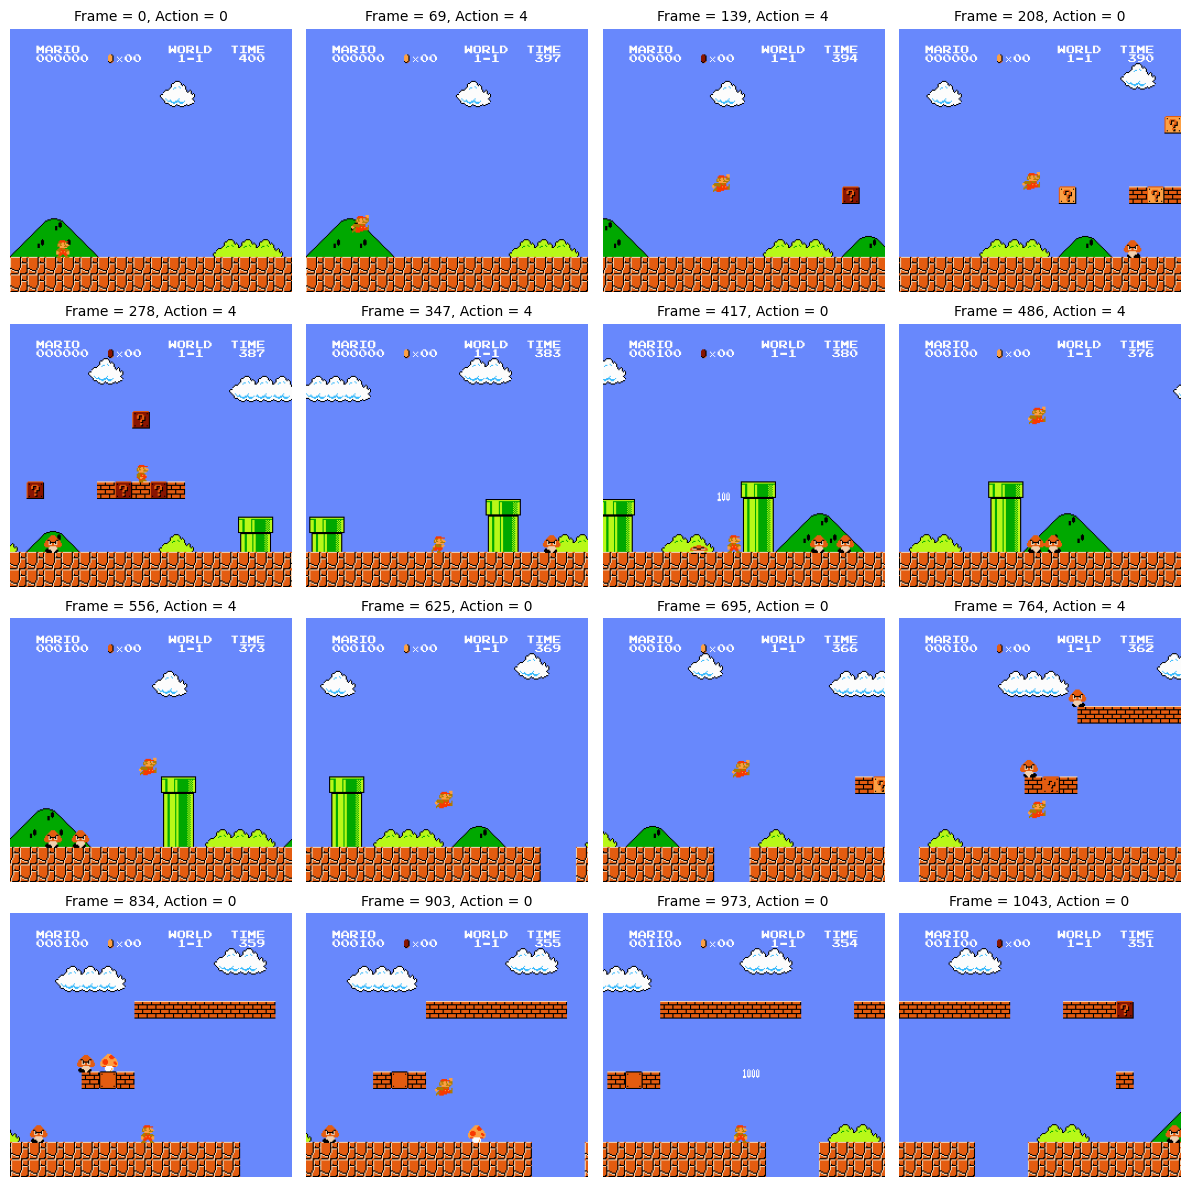

In [2]:
import json
import numpy as np
# get the action in the gameplay
# 1. Load the JSON file
with open("action_log.json", "r") as f:
    action_dict = json.load(f)

# 2. Extract ONLY the values and convert them to a NumPy array
# We cast to np.uint8 since action IDs are small integers (0-9)
actions_array = np.array(list(action_dict.values()), dtype=np.uint8)

# get the frames from the game
gameplay_footage = np.load('game_frames.npz', allow_pickle=True)

# 3. Extract the array using its key name
frames = gameplay_footage['game_frames']

# 4. Verify the dimensions and data type of your loaded array
print("Data Shape:", frames.shape)
print("Data Type:", frames.dtype)
print("Action saved:", len(actions_array))



# To plot them in one figure, with 4x4 axies
import matplotlib.pyplot as plt

# 1. Generate the 16 frame indices
# --- UPDATED: Safe calculation using the smaller total length ---
total_frames = min(frames.shape[0], len(actions_array))
# Generate 16 evenly spaced frame indices from 0 to the very last frame
# dtype=int converts the floating-point cuts into clean index integers
frame_indices = np.linspace(0, total_frames - 1, num=16, dtype=int)

# 2. Create a 4x4 subplot grid
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

# 3. Flatten the 4x4 axes array to a 1D array of 16 elements for easy looping
axes = axes.flatten()

# 4. Loop through and plot each frame
for idx, frame_num in enumerate(frame_indices):
    # Check to make sure the frame number actually exists in your data
    if frame_num < len(frames):
        axes[idx].imshow(frames[frame_num])
        axes[idx].set_title(f"Frame = {frame_num}, Action = {actions_array[frame_num]}", fontsize=10)
    else:
        # If your gameplay session was shorter than 900 frames, 
        # print a placeholder message for empty slots
        axes[idx].text(0.5, 0.5, "No Frame Data", ha='center', va='center')
    
    axes[idx].axis('off')  # Clean up layout by hiding axes lines

# 5. Adjust layout to avoid overlapping titles and show the grid
plt.tight_layout()
plt.show()

### 5-The Data Pipeline

Note: The code in this section is for illustrative purposes only. Please refer to Section 8 for the production-ready code.

---

The Mario DQN data pipeline is implemented as a chain of environment wrappers that progressively transform the outputs of `env.step(action)` before they reach the agent.
* Image processing
  * `GrayScaleObservation` converts RGB images `(240, 256, 3)` into grayscale images `(240, 256)`.
  * `ResizeObservation` downsamples the image to `(84, 84)` to reduce computational cost.
  * `NormalizeObservation` converts pixel values from `uint8` in the range `[0, 255]` to `float32` in the range `[0.0, 1.0]`.
  * `FrameStack` stacks the 4 most recent observations to produce a state representation of shape `(4, 84, 84)`, providing temporal information about motion.
* Reward accumulation
  * `SkipFrame(skip=4)` repeats the chosen action for 4 consecutive emulator frames.
  * Rewards from all 4 frames are summed into a single reward value.
  * Only the final observation is returned to the agent, reducing the number of observations processed by approximately 75% while preserving most important gameplay dynamics.

Overall, these wrappers transform the original game observation from an RGB image of shape `(240, 256, 3)` into a normalized state tensor of shape `(4, 84, 84)` suitable for Deep Q-Network training.

#### 5.0-Codemo of the data pipeline

In [4]:
import numpy as np
import torch
import gym
import gym_super_mario_bros
from nes_py.wrappers import JoypadSpace
from gym.wrappers import GrayScaleObservation, ResizeObservation, FrameStack

class SkipFrame(gym.Wrapper):
    def __init__(self, env, skip=4):
        super().__init__(env)
        self._skip = skip

    def step(self, action):
        total_reward = 0.0
        for _ in range(self._skip):
            # If using modern Gymnasium, change this to: obs, reward, terminated, truncated, info
            obs, reward, done, info = self.env.step(action)
            total_reward += reward
            if done:
                break
        return obs, total_reward, done, info

class NormalizeObservation(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        # Updates the observation space bounds to [0.0, 1.0]
        self.observation_space = gym.spaces.Box(
            low=0.0,
            high=1.0, 
            shape=self.env.observation_space.shape,
            dtype=np.float32
        )

    def observation(self, obs):
        # Convert to float32 and scale
        return np.array(obs).astype(np.float32) / 255.0

# Define custom action space
CUSTOM_ACTIONS = [
    ['NOOP'],
    ['A'],
    ['right', 'A', 'B']
]

# Create and wrap environment
env = gym_super_mario_bros.make("SuperMarioBros-1-1-v0")
env = JoypadSpace(env, CUSTOM_ACTIONS)
print("Original:", env.observation_space.shape)


# --- Preprocessing Pipeline ---
env = SkipFrame(env, skip=4)
print("After SkipFrame:", env.observation_space.shape)
env = GrayScaleObservation(env, keep_dim=False)
print("After GrayScaleObservation:", env.observation_space.shape)
env = ResizeObservation(env, shape=84)
print("After ResizeObservation:", env.observation_space.shape)
env = NormalizeObservation(env)  # Normalize individual 84x84 frames first
print("After NormalizeObservation:", env.observation_space.shape)

env = FrameStack(env, num_stack=4)  
# Stack normalized frames into (4, 84, 84) Lazy Frame
# but numpy array will add the trailing dimension to (4, 84, 84, 1)
print("After FrameStack:", env.observation_space.shape)

# Reset environment
# Note: If using Gym v0.26+, use: obs, info = env.reset()
obs = env.reset()

# Step execution test
action = env.action_space.sample()
obs, reward, done, info = env.step(action)

# obs is in Lazy frames format now
print("Observation type:", type(obs))

# Convert it to numpy array
# lazy frames convert cleanly to numpy array here
obs_array = np.array(obs, dtype=np.float32)
print("Observation shape with grayscale chanel:", obs_array.shape)
# lazy frame to numpy array will turn obs_array.shape into (4, 84, 84, 1)
# we can remove the last dimension
obs_array = np.squeeze(obs_array, axis=-1)
print("Observation converted to type:", type(obs_array))
print("Observation shape without grayscale chanel:", obs_array.shape)  # Should be (4, 84, 84)

# Convert it to PyTorch Tensor
obs_tensor = torch.tensor(obs_array).unsqueeze(0)  # Shape: (1, 4, 84, 84)
print("Tensor shape for NN input:", obs_tensor.shape)

print("Reward:", reward)
print("Done:", done)


Original: (240, 256, 3)
,,,,After SkipFrame: (240, 256, 3)
,,,,After GrayScaleObservation: (240, 256)
,,,,After ResizeObservation: (84, 84)
,,,,After NormalizeObservation: (84, 84)
,,,,After FrameStack: (4, 84, 84)
,,,,Observation type: <class 'gym.wrappers.frame_stack.LazyFrames'>
,,,,Observation shape with grayscale chanel: (4, 84, 84, 1)
,,,,Observation converted to type: <class 'numpy.ndarray'>
,,,,Observation shape without grayscale chanel: (4, 84, 84)
,,,,Tensor shape for NN input: torch.Size([1, 4, 84, 84])
,,,,Reward: 0.0
,,,,Done: False


#### 5.1-understanding the Mario DQN Data Pipeline

Although this sequence is commonly called a "data preprocessing pipeline," it is implemented as a chain of wrapper subclasses around the original environment. Each wrapper intercepts calls to methods such as `step()` and `reset()`, transforms the observations, rewards, or actions, and then passes the result to the next wrapper. As a result, the agent still calls `env.step(action)`, but the returned `next_state` has been progressively transformed from the original `(240, 256, 3)` RGB image into a normalized `(4, 84, 84)` tensor suitable for a Deep Q-Network. This is an example of the Decorator design pattern in object-oriented programming.

```pyton
env = gym_super_mario_bros.make("SuperMarioBros-1-1-v0")
env = SkipFrame(env, skip=4)
env = GrayScaleObservation(env, keep_dim=False)
env = ResizeObservation(env, shape=84)
env = NormalizeObservation(env)
env = FrameStack(env, num_stack=4)
```
5.1.1-`env = gym_super_mario_bros.make("SuperMarioBros-1-1-v0")`
* This initializes the NES emulator and game world but does not produce any observations yet.
* The first state is produced when `env.reset()` is called.
* Subsequent states are produced whenever `env.step(action)` is called.
  * For example: `next_state, reward, done, info = env.step(action=2)`, where:
    * `next_state`: A NumPy array representing the current game screen, with Shape: `(240, 256, 3)`, it means the game screen is 240 pixels high, 256 pixels wide, and contains 3 color channels (Red, Green, Blue).
    * `reward`: A numerical value indicating how beneficial the chosen action was. e.g., positive rewards are generally associated with forward progress, scoring points, or completing objectives.
    * `done`: A Boolean value indicating whether the episode has ended. It becomes `True` when Mario dies, runs out of time, completes the level, or otherwise reaches a terminal state.
    * `info`: A dictionary containing additional game-state information that may be useful for debugging or analysis. Example:
      * `{"coins": 0,  "flag_get": false, "life": 3, "score": 0, "stage": 1, "status": "small", "time": 400, "world": 1, "x_pos": 40, "y_pos": 79}`
* One additional detail: in modern Gym/Gymnasium versions, `step()` may return five values: `obs, reward, terminated, truncated, info`

5.1.2-`env = SkipFrame(env, skip=4)`
* Mario moves quickly, and consecutive emulator frames are often very similar.
* This wrapper repeats the AI's chosen action across 4 consecutive emulator frames.
  * The environment still executes all 4 frames internally.
  * For example, if the agent chooses the action "move right", the wrapper effectively executes:
    * Frame 1: move right
    * Frame 2: move right
    * Frame 3: move right
    * Frame 4: move right
* Rewards from all 4 frames are accumulated into a single total reward.
* Only the observation from the final (4th) frame is returned to the agent.
* This reduces the number of observations processed by the neural network by approximately 75%, allowing faster training while preserving most of the important game dynamics.
* SkipFrame modifies the behavior of `env.step(action)` but does not alter the observation format.
* The returned `next_state` is still an RGB NumPy array with shape `(240, 256, 3)`.

5.1.3-`env = GrayScaleObservation(env, keep_dim=False)`
* The neural network usually does not need full color information to learn effective Mario gameplay.
* This wrapper converts the 3-channel RGB image into a single-channel grayscale image using luminance weighting.
* Because `keep_dim=False`, the channel dimension is removed entirely.
* The observation changes from shape `(240, 256, 3)` to `(240, 256)`.
  * side note: `keep_dim=False` removes the grayscale channel for each frame, but (5.1.6) `FrameStack`'s `LazyFrames` in `gym==0.25.2` can still produce a stacked observation that ends up as `(4, 84, 84, 1)` when converted to NumPy.
  * `LazyFrames` is a memory-saving container used by `gym` `FrameStack`.
* The returned `next_state` is now a 2D NumPy array representing pixel brightness values.

5.1.4-`env = ResizeObservation(env, shape=84)`
* The original game screen contains far more pixels than the neural network needs.
* This wrapper downsamples the grayscale image to reduce memory usage and computational cost.
* It rescales the entire image from `(240,256)` to `(84,84)` using image interpolation `cv2.resize()`, preserving the overall scene while reducing detail.
* The returned `next_state` remains a grayscale NumPy array, but at a much lower resolution.

5.1.5-`env = NormalizeObservation(env)`
* So far, the data pipeline has reduced the image dimensions but has not changed the pixel value range.
* Raw grayscale pixel values are stored as unsigned 8-bit integers (`uint8`) ranging from 0 to 255.
* Neural networks generally train more efficiently when input features are scaled to a consistent numerical range.
* This wrapper converts pixel intensities from the integer range `[0, 255]` to the floating-point range `[0.0, 1.0]`.
* Every pixel value is divided by `255.0`.
* The observation data type is converted from `uint8` to `float32`, which is the standard format expected by most deep learning frameworks such as PyTorch.
* The observation shape remains `(84, 84)`.
* The final output is a normalized `float32` NumPy array that can be fed directly into a Deep Q-Network (DQN).

5.1.6-`env = FrameStack(env, num_stack=4)`
* A single static image cannot show motion.
  * If Mario is next to a Goomba, a single image cannot tell whether Mario is moving left, moving right, or standing still.
  * Stacking multiple recent frames allows the network to infer motion and direction.
* This wrapper stacks the 4 most recent observations `(ft-3, ft-2, ft-1, ft)` along a new dimension.
  * For example, after several SkipFrame steps, the stack may contain frames `[4, 8, 12, 16]`.
* This gives the AI temporal awareness, allowing it to infer the direction and approximate velocity of moving objects.
* The observation shape changes from `(84, 84)` to `(4, 84, 84)`.

5.1.7-Codemo to inspect the Outputs along the pipeline
* `print(f"{next_state.shape},\n {reward},\n {done},\n {info}")`

5.2-Understanding the methods in `gym`
* Starting the Game, `env.reset()`
  * What it does: This initializes (or re-initializes) the NES emulator and places Mario at the starting position of World 1-1, clearing any previous episode data.
  * It returns the first observation of the game: `obs = env.reset()`.
  * Because of the wrappers (SkipFrame, GrayScale, Resize, FrameStack), this initial observation has already been transformed into a tensor of shape `(4, 84, 84)`.
    * Since there is no history at the start, the frame stack is filled by repeating the first observation 4 times (e.g., [1, 1, 1, 1]).
    * As the game progresses, the stack is updated with new frames over time, e.g., (t-3, t-2, t-1, t), where each step is separated by SkipFrame logic (e.g., frames 1, 5, 9, 13).
* Taking One Step `next_state, reward, done, info = env.step(action)`
  * This sends an action index (e.g., `action=2`) to the environment, which corresponds to a predefined button combination (such as Right + A or Right + B depending on the action set used).
  * The emulator executes this action and advances the game forward.
    * As `SkipFrame(skip=4)` is applied, the same action is repeated for 4 consecutive emulator frames internally, and the rewards are accumulated over those frames.
* The Outputs:
  * The environment returns four key components:

  * `next_state`, also aliased as `obs` (observation):
    * The next observation after applying all wrappers.
    * A stacked grayscale state with shape `(4, 84, 84)`, representing recent game history.

  * `reward`:
    * A numerical signal representing how beneficial the action was.
    * Typically increases when Mario makes progress (moving right, collecting coins, defeating enemies) and decreases on failure or time loss.

  * `done`:
    * A boolean flag indicating whether the episode has ended.
    * Becomes `True` when Mario dies, completes the level, or runs out of time.

  * `info`:
    * A dictionary containing extra diagnostic game data such as score, coins, world, stage, Mario’s position, remaining time, and status.


### 6-The CNN

#### 6.0 Note on Code

The code in this section is for illustrative purposes only. Please refer to Section 8 for the production-ready code.

#### 6.1-Codemo of the **2D Convolutional Neural Network** Block
* The `MarioNet` class, defined as `class MarioNet(nn.Module):`, is a subclass of PyTorch's `nn.Module` base class.

In [1]:
import torch
import torch.nn as nn
import copy

class MarioNet(nn.Module):
  '''
  mini cnn structure
  input -> (conv2d + relu) x 3 -> flatten -> (dense + relu) x 2 -> output
  '''
  def __init__(self, input_dim, output_dim):
      super().__init__()
      c, h, w = input_dim

      if h != 84:
          raise ValueError(f"Expecting input height: 84, got: {h}")
      if w != 84:
          raise ValueError(f"Expecting input width: 84, got: {w}")

      self.online = nn.Sequential(
          nn.Conv2d(in_channels=c, out_channels=32, kernel_size=8, stride=4),
          nn.ReLU(),
          nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4, stride=2),
          nn.ReLU(),
          nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1),
          nn.ReLU(),
          nn.Flatten(),
          nn.Linear(3136, 512),
          nn.ReLU(),
          nn.Linear(512, output_dim)
      )

      self.target = copy.deepcopy(self.online)

      # Q_target parameters are frozen.
      for p in self.target.parameters():
          p.requires_grad = False

  def forward(self, input, model):
      if model == 'online':
          return self.online(input)
      elif model == 'target':
          return self.target(input)

<class 'ModuleNotFoundError'>: No module named 'torch'

#### 6.2-Check each layers, and the flow of tensors
* input, output size

In [6]:
# PyTorch expected input format: (Batch, Channels, Height, Width)
# Example: a single stacked state with 4 grayscale frames of size 84x84
input_dim = (4, 84, 84)

# 3 possible actions:
# CUSTOM_ACTIONS = [['NOOP'], ['A'], ['right', 'A', 'B']]
output_dim = 3

# Create a MarioNet instance
model = MarioNet(input_dim, output_dim)

print(model)

MarioNet(
,,,,  (online): Sequential(
,,,,    (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
,,,,    (1): ReLU()
,,,,    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
,,,,    (3): ReLU()
,,,,    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
,,,,    (5): ReLU()
,,,,    (6): Flatten(start_dim=1, end_dim=-1)
,,,,    (7): Linear(in_features=3136, out_features=512, bias=True)
,,,,    (8): ReLU()
,,,,    (9): Linear(in_features=512, out_features=3, bias=True)
,,,,  )
,,,,  (target): Sequential(
,,,,    (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
,,,,    (1): ReLU()
,,,,    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
,,,,    (3): ReLU()
,,,,    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
,,,,    (5): ReLU()
,,,,    (6): Flatten(start_dim=1, end_dim=-1)
,,,,    (7): Linear(in_features=3136, out_features=512, bias=True)
,,,,    (8): ReLU()
,,,,    (9): Linear(in_features=512, out_features=3, bias=True)
,,,,  )
,,,,)


#### 6.3-Plot the structure of the CNN model. 
* This requires  `graphviz`
  ```python
  from torchview import draw_graph
  model = MarioNet((4, 84, 84), 3)
  graph = draw_graph(
      model.online,
      input_size=(1, 4, 84, 84),
      expand_nested=True
  )
  graph.visual_graph
  ```

#### 6.4-Understanding the Deep Q-Network

6.4.1-A Table Q-Network, or **Tabular Q-Learning**, becomes a **Deep Q-Network (DQN)** when we replace the explicit Q-table with a neural network that **approximates** the Q-function.

The core shift: lookup table vs. function approximation
* In tabular Q-learning, the agent stores a separate Q-value for every state-action pair $(s, a)$ in a table.
* This works well only when the state space and action space are small enough to list explicitly.
* As the environment becomes larger or higher-dimensional, a Q-table becomes impractical:
  * it may require too much memory,
  * many states may rarely be visited,
  * and it cannot generalize across similar states.
* A neural network addresses this by learning a function: $Q(s, a; \theta)$, instead of storing every Q-value explicitly in a table.

In Tabular Q-Learning: the agent’s memory is a 2D table:
* **Rows** = possible states $S$
* **Columns** = possible actions $A$
* **Each cell** = the Q-value $Q(s, a)$, the expected future return for taking action $a$ in state $s$
* Example Q-table
| State | Action 1 | Action 2 | Action 3 |
|---|---:|---:|---:|
| State 1 | 1.5 | -0.2 | 2.4 |
| State 2 | 0.0 | 4.1 | -1.1 |
* The limitation is that we cannot keep adding rows forever as the number of possible states grows.

In a Deep Q-Network: the table is replaced by a neural network.
* **Input layer:** receives the current state $s$, for example, a stacked set of game frames such as a $4 \times 84 \times 84$ FrameStack
* **Output layer:** produces a vector of estimated Q-values, one for each possible action
* **No explicit table:** the network computes approximate Q-values rather than looking them up from memory
* So instead of storing a value for every possible $(s, a)$ pair, the model learns to estimate: $Q(s, a; \theta)$ from the state input.


6.4.2-Understanding the Deep Q-Network Output
* This network is a **Deep Q-Network (DQN)**.
* The final output is **not a class prediction**.
* Instead, it outputs a **Q-value for each possible action** Mario can take.
* A Q-value estimates the **expected future discounted reward** if Mario takes that action in the current state and then continues following the policy.
```python
# PyTorch expected input format: (Batch, Channels, Height, Width)
# Example: a single stacked state with 4 grayscale frames of size 84x84
input_dim = (4, 84, 84)

# 3 possible actions:
# CUSTOM_ACTIONS = [['NOOP'], ['A'], ['right', 'A', 'B']]
output_dim = 3

# Create a MarioNet instance
model = MarioNet(input_dim, output_dim)

# Example input tensor
x = torch.randn(4, 84, 84)

# Get Q-values from the online network
q_values = model(x, "online")
print(q_values)

# Example output:
# tensor([[ 1.23, -0.45, 2.87]])
```

If the network predicts:

```python
tensor([[ 1.23, -0.45, 2.87]])
```

this means:
* If Mario takes action `0` (`NOOP`), the estimated future reward is `1.23`
* If Mario takes action `1` (`A`, jump), the estimated future reward is `-0.45`
* If Mario takes action `2` (`right + A + B`), the estimated future reward is `2.87`

The agent chooses the action with the highest Q-value:
```python
action = torch.argmax(q_values, dim=1).item()
```
Here, the highest Q-value is `2.87`, so:
```python
action = 2
```
This action is then passed to the environment:
```python
obs, reward, done, info = env.step(action)
```


#### 6.5-Why two networks?
```python
self.online
self.target
```

This is the standard DQN design.
* Online network
  * Learns every training step.
  * Chooses actions.
* Target network
  * Frozen copy.
  * Used to compute stable training targets.
  * The target network is periodically updated:


#### 6.6-Understanding the *double* in **Double DQN**

Having two networks, `self.online` and `self.target`, is necessary for **Double DQN**, but it is not what makes the algorithm "double." These two networks are also used in a standard DQN. The target network was introduced to stabilize training by providing a slowly changing target.
* We only periodically copy the weights from `self.online` to `self.target`.

6.6.0-What differs between standard DQN and Double DQN is how the TD target $Y_t$ is computed.
* The "double" in Double DQN refers to using two networks for two different purposes during target calculation.
* This decoupling of action selection and action evaluation is what makes Double DQN "double," not merely the existence of `self.online` and `self.target`.

6.6.1-Standard DQN
* The target network handles both selection and evaluation simultaneously via the $\max$ operator:
$$Y_t = R_{t+1} + \gamma \max_{a} Q_{target}(S_{t+1}, a)$$
* The same network (`Q_target`) is used to both:
  * Determine which action has the highest Q-value.
  * Provide the value of that chosen action.
* This can lead to overestimation of Q-values because the same estimates are used for both selection and evaluation. Randomly overestimated actions are more likely to be selected by the `max` operator, causing Q-values to become systematically too large over time.

6.6.2-Double DQN
* We decouple the selection (using the online network $\theta$) from the evaluation (using the target network $\theta^-$):
$$Y_t = R_{t+1} + \gamma Q_{target}\left(S_{t+1}, \arg\max_{a} Q_{online}(S_{t+1}, a)\right)$$
* This reduces overestimation bias because the network choosing the action is different from the network evaluating its value.
| Step | Standard DQN | Double DQN |
| --- | --- | --- |
| **Action Selection** (Which action is best?) | `argmax Q_target(s', a')` | `argmax Q_online(s', a')` |
| **Action Evaluation** (What is it worth?) | `Q_target(s', best_action_from_target)` | `Q_target(s', best_action_from_online)` |
| **The Core Benefit** | Susceptible to overestimation bias. | Mitigates overestimation bias via decoupling. |

6.6.3-Example
```python
# Double DQN
next_q_online = self.online(next_state)
best_action = torch.argmax(next_q_online, dim=1)

next_q_target = self.target(next_state)
target_q = next_q_target.gather(1, best_action.unsqueeze(1))
```

Although both standard DQN and Double DQN maintain an online network and a target network, the key innovation of Double DQN is how those networks are used. By separating action selection from action evaluation during TD target computation, Double DQN produces more reliable value estimates and reduces overestimation bias.


### 7-The Agent

The code in this section is for illustrative purposes only. Please refer to Section 8 for the production-ready code.

---

* This is a Python class representing Mario, and it is a good example of subclassing.
* We will progressively add Mario’s methods through multiple layers of subclassing.
* As a side note, I’m fairly confident that mastering subclassing is an important step toward being able to write your own deep learning models.
* Of course, you would also need to understand:
  * tensors and shapes,
  * forward passes,
  * loss functions,
  * backpropagation,
  * optimization,
  * training loops,
  * the deep learning framework itself,
  * and checkpointing design.

#### 7.0-Start by building a proper framework for the `Mario` class, including all its attributes and empty methods.
* The initial frame class will be named `MarioFrame`.
* We can use subclassing later to fill in the detailed functionality for each method.
* Note: Even though Python allows a subclass to share a name with its parent class under certain conditions (e.g., `class Mario(Mario):`), we will use distinct names for the frame class and intermediate subclasses before finalizing on the name `Mario`. This is done for clarity.

In [1]:
from collections import deque
"""
The maxlen Feature (Perfect for History/Buffers)
You can set a maximum length when creating a deque.
If the deque is full and you add a new item, it automatically discards the item
from the opposite side.
This is perfect for tracking "Recent Items" or building a circular buffer.
"""


def first_if_tuple(x):
    """
    Some Gym versions return (obs, info) tuples from reset()/step().
    This unwraps the observation if a tuple slipped through, otherwise
    returns x unchanged. Guards act() and cache() against version drift.
    """
    return x[0] if isinstance(x, tuple) else x


class MarioFrame:
    def __init__(self, state_dim, action_dim, save_dir):
        """
        Initialize the Mario agent.

        This implementation is CPU-only to make the project easier
        to run on a wider range of machines.
        """

        # Environment dimensions
        self.state_dim = state_dim
        self.action_dim = action_dim

        # Directory used for saving model checkpoints
        self.save_dir = save_dir

        # Deep Q-Network (DQN) used to estimate Q-values
        self.net = MarioNet(
            self.state_dim,
            self.action_dim
        ).float()

        # Epsilon-greedy exploration parameters
        # Start with full exploration and gradually
        # reduce exploration over time.
        self.exploration_rate = 1.0
        self.exploration_rate_decay = 0.99999975
        self.exploration_rate_min = 0.1

        # Total number of environment steps taken
        self.curr_step = 0

        # Save the model every 500,000 steps
        self.save_every = int(5e5)

        # Replay buffer for storing past experiences:
        # (state, next_state, action, reward, done)
        self.memory = deque(maxlen=100000)

        # Number of experiences sampled from the
        # replay buffer during each training update
        self.batch_size = 32

    def act(self, state):
        """
        Given a state, choose an epsilon-greedy action.
        """
        pass

    def cache(self, state, next_state, action, reward, done):
        """
        Store experience in replay memory.

        experience =
        (state, next_state, action, reward, done)
        """
        pass

    def recall(self):
        """
        Sample a batch of experiences from memory.
        """
        pass

    def learn(self):
        """
        Update Q-network using sampled experiences.
        """
        pass

Create a demo instance for the `class MarioFrame:`

In [11]:
import random
from pathlib import Path

# Create checkpoints folder in the current project directory
save_dir = Path("./checkpoints")
save_dir.mkdir(exist_ok=True)

# Create Mario agent
FrameDemo = MarioFrame(
    state_dim=(4, 84, 84),  # 4 stacked grayscale frames
    action_dim=3,           # 3 custom actions
    save_dir=save_dir
)

# Inspect attributes
print("State Dimension:", FrameDemo.state_dim)
print("Action Dimension:", FrameDemo.action_dim)
print("Exploration Rate:", FrameDemo.exploration_rate)
print("Batch Size:", FrameDemo.batch_size)
print("Current Step:", FrameDemo.curr_step)
print("Replay Buffer Size:", len(FrameDemo.memory))

# Simulate a few experiences being stored
FrameDemo.memory.append(("state_1", "state_2", 3, 1.0, False))
FrameDemo.memory.append(("state_2", "state_3", 1, 0.5, False))
FrameDemo.memory.append(("state_3", "state_4", 2, 2.0, True))

print("\nReplay Buffer:")
for experience in FrameDemo.memory:
    print(experience)

# Sample a mini-batch (similar to what recall() will do)
batch = random.sample(FrameDemo.memory, 2)

print("\nRandom Batch:")
for experience in batch:
    print(experience)

State Dimension: (4, 84, 84)
,,,,Action Dimension: 3
,,,,Exploration Rate: 1.0
,,,,Batch Size: 32
,,,,Current Step: 0
,,,,Replay Buffer Size: 0
,,,,
,,,,Replay Buffer:
,,,,('state_1', 'state_2', 3, 1.0, False)
,,,,('state_2', 'state_3', 1, 0.5, False)
,,,,('state_3', 'state_4', 2, 2.0, True)
,,,,
,,,,Random Batch:
,,,,('state_3', 'state_4', 2, 2.0, True)
,,,,('state_1', 'state_2', 3, 1.0, False)


#### 7.1-Next, we'll create a subclass named `MarioAct`. 
* It will inherit from the parent class `MarioFrame` and override its placeholder method `act(self, state)`.

In [12]:
import numpy as np
import torch


class MarioAct(MarioFrame):
    def __init__(self, state_dim, action_dim, save_dir):
        super().__init__(state_dim, action_dim, save_dir)

    def act(self, state):
        """
        Given a state, choose an epsilon-greedy action and update value of step.

        Inputs:
            state (LazyFrame): Current observation

        Returns:
            action_idx (int): Selected action
        """

        # EXPLORE
        if np.random.rand() < self.exploration_rate:
            action_idx = np.random.randint(self.action_dim)

        # EXPLOIT
        else:
            state = first_if_tuple(state).__array__()
            state = torch.tensor(state, dtype=torch.float32)
            state = state.unsqueeze(0)

            action_values = self.net(state, model="online")
            action_idx = torch.argmax(action_values, dim=1).item()

        # Decrease exploration rate
        self.exploration_rate *= self.exploration_rate_decay
        self.exploration_rate = max(
            self.exploration_rate_min,
            self.exploration_rate
        )

        # Increment step counter
        self.curr_step += 1

        return action_idx

Below is an instance demo.

In [14]:
import numpy as np
from pathlib import Path

# Create checkpoints folder
save_dir = Path("./checkpoints")
save_dir.mkdir(exist_ok=True)

# Create Mario agent
ActDemo = MarioAct(
    state_dim=(4, 84, 84),
    action_dim=7,
    save_dir=save_dir
)

# Fake state:
# 4 stacked grayscale frames, each 84x84
state = np.random.randint(
    0,
    256,
    size=(4, 84, 84),
    dtype=np.uint8
)

print("Initial Exploration Rate:",
      ActDemo.exploration_rate)
print("Initial Step Count:",
      ActDemo.curr_step)

# Take 5 actions
for i in range(5):
    action = ActDemo.act(state)

    print(
        f"Step {ActDemo.curr_step}: "
        f"Action={action}, "
        f"Exploration Rate={ActDemo.exploration_rate:.6f}"
    )

Initial Exploration Rate: 1.0
,,,,Initial Step Count: 0
,,,,Step 1: Action=3, Exploration Rate=1.000000
,,,,Step 2: Action=0, Exploration Rate=1.000000
,,,,Step 3: Action=1, Exploration Rate=0.999999
,,,,Step 4: Action=4, Exploration Rate=0.999999
,,,,Step 5: Action=4, Exploration Rate=0.999999


#### 7.2-`MarioCache`
* It continues the subclassing layers, inheriting from the intermediate class `MarioAct` and overriding its `cache(self, experience):` method.
* `cache()`: Each time Mario performs an action, he stores the `experience` to his memory. His experience includes the current `state`, `action` performed, `reward` from the action, the `next state`, and whether the game is `done`.

In [15]:
class MarioCache(MarioAct):
    def __init__(self, state_dim, action_dim, save_dir):
        super().__init__(state_dim, action_dim, save_dir)

    def cache(self, state, next_state, action, reward, done):

        state = first_if_tuple(state).__array__()
        next_state = first_if_tuple(next_state).__array__()

        state = torch.tensor(state, dtype=torch.float32)
        next_state = torch.tensor(next_state, dtype=torch.float32)

        action = torch.tensor([action], dtype=torch.long)
        reward = torch.tensor([reward], dtype=torch.float32)
        done = torch.tensor([done], dtype=torch.bool)

        self.memory.append(
            (state, next_state, action, reward, done)
        )

And the instance demo:

In [16]:
import numpy as np
from pathlib import Path

# Create checkpoints folder
save_dir = Path("./checkpoints")
save_dir.mkdir(exist_ok=True)

# Create Mario agent
CacheDemo = MarioCache(
    state_dim=(4, 84, 84),
    action_dim=7,
    save_dir=save_dir
)

print("Replay Buffer Size:",
      len(CacheDemo.memory))

# Create a fake transition
state = np.random.randint(
    0, 256,
    size=(4, 84, 84),
    dtype=np.uint8
)

next_state = np.random.randint(
    0, 256,
    size=(4, 84, 84),
    dtype=np.uint8
)

action = 3
reward = 1.0
done = False

# Store transition
CacheDemo.cache(
    state,
    next_state,
    action,
    reward,
    done
)

print("\nReplay Buffer Size:",
      len(CacheDemo.memory))

# Inspect stored experience
stored_state, stored_next_state, stored_action, stored_reward, stored_done = (
    CacheDemo.memory[0]
)

print("\nStored Experience:")
print("State Shape:", stored_state.shape)
print("Next State Shape:", stored_next_state.shape)
print("Action:", stored_action)
print("Reward:", stored_reward)
print("Done:", stored_done)

print("\nTensor Types:")
print(type(stored_state))
print(type(stored_action))
print(type(stored_reward))
print(type(stored_done))

Replay Buffer Size: 0
,,,,
,,,,Replay Buffer Size: 1
,,,,
,,,,Stored Experience:
,,,,State Shape: torch.Size([4, 84, 84])
,,,,Next State Shape: torch.Size([4, 84, 84])
,,,,Action: tensor([3])
,,,,Reward: tensor([1.])
,,,,Done: tensor([False])
,,,,
,,,,Tensor Types:
,,,,<class 'torch.Tensor'>
,,,,<class 'torch.Tensor'>
,,,,<class 'torch.Tensor'>
,,,,<class 'torch.Tensor'>


#### 7.3-`MarioRecall`
* It continues the subclassing layers, inheriting from the intermediate class `MarioCache` and overriding its `recall(self):` method.
* In `recall()`, Mario randomly samples a batch of experiences from `self.memory`, which was created in `MarioCache`, and uses them to learn the game.

In [17]:
import random
import torch

class MarioRecall(MarioCache):
    def __init__(self, state_dim, action_dim, save_dir):
        super().__init__(state_dim, action_dim, save_dir)

    def recall(self):
        """
        Randomly sample a batch of experiences from replay memory.

        Returns:
            state      : Tensor [batch_size, ...]
            next_state : Tensor [batch_size, ...]
            action     : Tensor [batch_size]
            reward     : Tensor [batch_size]
            done       : Tensor [batch_size]
        """

        batch = random.sample(self.memory, self.batch_size)

        state, next_state, action, reward, done = map(
            torch.stack,
            zip(*batch)
        )

        return (
            state,
            next_state,
            action.squeeze(),
            reward.squeeze(),
            done.squeeze()
        )

Check down below for an instance demo

In [18]:
import numpy as np
from pathlib import Path

# Create checkpoints folder
save_dir = Path("./checkpoints")
save_dir.mkdir(exist_ok=True)

# Create Mario agent
RecallDemo = MarioRecall(
    state_dim=(4, 84, 84),
    action_dim=7,
    save_dir=save_dir
)

print("Batch Size:", RecallDemo.batch_size)

# Fill replay memory with 32 experiences
for i in range(RecallDemo.batch_size):

    state = np.random.randint(
        0, 256,
        size=(4, 84, 84),
        dtype=np.uint8
    )

    next_state = np.random.randint(
        0, 256,
        size=(4, 84, 84),
        dtype=np.uint8
    )

    action = np.random.randint(RecallDemo.action_dim)
    reward = np.random.randn()
    done = (i % 10 == 0)

    RecallDemo.cache(
        state,
        next_state,
        action,
        reward,
        done
    )

print("Replay Buffer Size:",
      len(RecallDemo.memory))

# Sample a batch
state, next_state, action, reward, done = (
    RecallDemo.recall()
)

print("\nReturned Tensors:")
print("State Shape:", state.shape)
print("Next State Shape:", next_state.shape)
print("Action Shape:", action.shape)
print("Reward Shape:", reward.shape)
print("Done Shape:", done.shape)

print("\nExample Values:")
print("Actions:", action[:5])
print("Rewards:", reward[:5])
print("Done Flags:", done[:5])

Batch Size: 32
,,,,Replay Buffer Size: 32
,,,,
,,,,Returned Tensors:
,,,,State Shape: torch.Size([32, 4, 84, 84])
,,,,Next State Shape: torch.Size([32, 4, 84, 84])
,,,,Action Shape: torch.Size([32])
,,,,Reward Shape: torch.Size([32])
,,,,Done Shape: torch.Size([32])
,,,,
,,,,Example Values:
,,,,Actions: tensor([1, 0, 1, 0, 2])
,,,,Rewards: tensor([-0.8543,  1.2044,  0.2693, -0.4772, -0.5673])
,,,,Done Flags: tensor([False,  True, False, False, False])


#### 7.4-The finalized `Mario` class, with integraton of the **Learn** funcitonality

---

7.4.1 — Understanding the Loss Function

Temporal Difference (TD) Learning
* Temporal Difference (TD) learning is the core mechanism used in Deep Q-Networks (DQN) to update **Q-value estimates**.
* Instead of waiting until the end of an episode to evaluate an action, TD learning updates the network from **single-step transitions**.

---

Loss Function Chain
* TD Estimate $\rightarrow$ TD Target $\rightarrow$ TD Error $\rightarrow$ Loss Function

---

TD Estimate
* In each step, the CNN (its **Online Network**) takes the state tensor ($s$) of shape `(1, 4, 84, 84)` and outputs a vector of Q-values.
* For our implementation `CUSTOM_ACTIONS = [['NOOP'], ['A'], ['right', 'A', 'B']]`, let's say the output is: `tensor([[ 1.23, -0.45, 2.87]])`
* The agent looks at these options and chooses an action ($a$), let's say it chooses `['right', 'A', 'B']` (index = 2).
* To calculate the loss, we isolate **only** the predicted Q-value for the action that was actually taken:
* This is the **TD Estimate** $Q_{\text{online}}(s, a) = 2.87$
  * Note: "TD" stands for Temporal Difference, but the value itself is not the "temporal difference"; it is the current estimate of the action value.

---

Step the Environment and Observe Reality
* The agent executes `['right', 'A', 'B']` in the Gym emulator. The environment advances and returns a feedback tuple: `obs, reward, done, info = env.step(action=2)`
  * `obs` is the next state ($s'$): the next frame-stack observation.
  * `reward` ($r$): suppose Mario moves forward and collects a coin, producing a reward of $+10$.
  * `done`: a boolean flag indicating whether the episode has ended (for example, Mario died or completed the level).
  * `info`: a dictionary containing additional game information such as score, coins, world, stage, Mario's position, remaining time, and status.

---

Predict the Future Value, with Double DQN
* This tutorial uses **Double DQN**, which splits "what's the best next action?" from "how good is it?" across the two networks.
* This decoupling is what reduces the overestimation bias that plain DQN suffers from (a single network both *picking* and *valuing* the max tends to chase its own noise upward).

Step 1 — Online network selects the next action ($a'$).
* Pass the `next_state` tensor ($s'$) into the **Online Network**.
* Take the argmax of its output to choose the next action: $a' = \displaystyle\arg\max_{a'} Q_{\text{online}}(s', a')$
* Suppose the online network's best next action is index 2.

Step 2 — Target network evaluates that chosen action.
* Pass the same `next_state` tensor into the **Target Network** (a periodically updated copy of the online network).
* Look up the value of the action that the *online* network selected
  * we do **not** take the target network's own max:
  * $Q_{\text{target}}(s',\, a') = Q_{\text{target}}\big(s', \ \displaystyle\arg\max_{a'} Q_{\text{online}}(s', a')\big)$
* Suppose this value is $4.01$.

Compare to the vanilla DQN.
* Plain DQN collapses both steps into the target network and takes its max directly: $ \displaystyle\max_{a'} Q_{\text{target}}(s', a')$.
* Same network selects and evaluates, which is the source of the overestimation Double DQN fixes.

---

Calculate the TD Target ($Y$)
* Now we combine the immediate reward with our discounted prediction of future rewards to determine what the value of the chosen action should have been.
* $Y = r + \gamma\, Q_{\text{target}}\big(s',\  \displaystyle\arg\max_{a'} Q_{\text{online}}(s', a')\big) \cdot (1 - \text{done})$
  * $\gamma$ (Gamma): the discount factor (between 0 and 1) determining how much the agent cares about long-term vs. short-term rewards.
  * $(1 - \text{done})$: if Mario dies or completes the level, there is no future state to learn from. In that case `done = 1`, making $(1 - \text{done}) = 0$, which removes the future reward term and leaves only the final reward.
* Using our numbers:
  * reward $r = 10$
  * $\gamma = 0.99$
  * $Q_{\text{target}}(s', a') = 4.01$
  * done = False (0)
  * $Y = 10 + 0.99 \cdot 4.01 \cdot (1 - 0) \approx 13.97$
* This TD Target tells us that taking `['right', 'A', 'B']` from state $s$ ultimately appears to be worth about **13.97** in total expected reward.

---

Loss Function and Backpropagation
* Now we compare the **TD Target ($Y = 13.97$)** against our original **TD Estimate ($Q = 2.87$)**.
* The raw difference is your TD Error ($\delta$): $\delta = 13.97 - 2.87 = 11.10$
* Because a raw error of $11.10$ can cause aggressive gradient updates that might destabilize your Mario agent, we pass this difference through the **Huber Loss** (a.k.a. **Smooth L1 Loss** when the threshold is 1):
  * $\mathcal{L} = \text{Huber}(Y, Q_{\text{online}}(s, a))$

$$
\mathcal{L}(\delta) =
\begin{cases}
0.5\,\delta^2 & \text{if } |\delta| \le 1 \\
|\delta| - 0.5 & \text{if } |\delta| > 1
\end{cases}
$$

  * Since our error ($\delta = 11.10$) is greater than 1, Huber loss treats it linearly to protect the network from exploding gradients: $\mathcal{L} = 11.10 - 0.5 = 10.60$

> **Note on Huber vs. Smooth L1.** They are identical *here* because the changeover threshold is 1. In the general case Huber uses a threshold $\delta_h$ and the quadratic branch is scaled by it ($\tfrac{1}{2}\delta^2$ vs. $\tfrac{1}{2}\delta_h\,\delta^2$ style definitions), so the two are only interchangeable at $\delta_h = 1$. PyTorch's `SmoothL1Loss` and `HuberLoss(delta=1.0)` match at this setting.

With a value for the loss $\mathcal{L}$, we can do backpropagation to update the weights for $Q_{\text{online}}$:
  * As Mario samples inputs from his replay buffer, we compute the TD target and TD estimate, then backpropagate this loss down $Q_{\text{online}}$ to update its parameters $\theta_{\text{online}}$ ($\alpha$ is the learning rate `lr` passed to the `Adam` optimizer):
* $\theta_{\text{online}} \leftarrow \theta_{\text{online}} - \alpha \nabla(\mathcal{L})$
* $\theta_{\text{target}}$ does **not** update through backpropagation. Instead, we periodically copy $\theta_{\text{online}}$ to $\theta_{\text{target}}$: $\theta_{\text{target}} \leftarrow \theta_{\text{online}}$

In [19]:
class Mario(MarioRecall):
    def __init__(self, state_dim, action_dim, save_dir):
        # Chain the parent init so net, memory, batch_size, curr_step,
        # save_every, exploration_rate (+ decay/min), state/action dims,
        # and save_dir all get set up before we use them below.
        super().__init__(state_dim, action_dim, save_dir)

        self.gamma = 0.9

        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=0.00025)
        self.loss_fn = torch.nn.SmoothL1Loss()

        self.burnin = 1e5      # min experiences before training
        self.learn_every = 3   # experiences between Q_online updates
        self.sync_every = 1e4  # experiences between Q_target syncs

    def td_estimate(self, state, action):
        current_Q = self.net(state, model='online')[
            np.arange(0, self.batch_size), action
        ]
        return current_Q

    @torch.no_grad()
    def td_target(self, reward, next_state, done):
        # Double DQN: online net selects the best next action,
        # target net evaluates it.
        next_state_Q = self.net(next_state, model='online')
        best_action = torch.argmax(next_state_Q, axis=1)
        next_Q = self.net(next_state, model='target')[
            np.arange(0, self.batch_size), best_action
        ]
        return (reward + (1 - done.float()) * self.gamma * next_Q).float()

    def update_Q_online(self, td_estimate, td_target):
        loss = self.loss_fn(td_estimate, td_target)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return loss.item()

    def sync_Q_target(self):
        self.net.target.load_state_dict(self.net.online.state_dict())

    def save(self):
        save_path = self.save_dir / f"mario_net_{int(self.curr_step // self.save_every)}.chkpt"
        torch.save(
            {
                "model": self.net.state_dict(),
                "exploration_rate": self.exploration_rate
            },
            save_path
        )
        print(f"MarioNet saved to {save_path} at step {self.curr_step}")

    def learn(self):
        if self.curr_step % self.sync_every == 0:
            self.sync_Q_target()

        if self.curr_step % self.save_every == 0:
            self.save()

        if self.curr_step < self.burnin:
            return None, None

        if self.curr_step % self.learn_every != 0:
            return None, None

        # Sample from memory
        state, next_state, action, reward, done = self.recall()

        # Get TD Estimate
        td_est = self.td_estimate(state, action)

        # Get TD Target
        td_tgt = self.td_target(reward, next_state, done)

        # Backpropagate loss through Q_online
        loss = self.update_Q_online(td_est, td_tgt)

        return td_est.mean().item(), loss

The demo instance.

In [20]:
import numpy as np
from pathlib import Path

# Create checkpoints folder
save_dir = Path("./checkpoints")
save_dir.mkdir(exist_ok=True)

# Create Mario agent
MarioDemo = Mario(
    state_dim=(4, 84, 84),
    action_dim=7,
    save_dir=save_dir
)

# For demo purposes only:
# skip the normal 100,000-step burn-in
MarioDemo.burnin = 0

# Ensure learn() runs
MarioDemo.curr_step = MarioDemo.learn_every

# Fill replay memory with batch_size experiences
for _ in range(MarioDemo.batch_size):

    state = np.random.randint(
        0, 256,
        size=(4, 84, 84),
        dtype=np.uint8
    )

    next_state = np.random.randint(
        0, 256,
        size=(4, 84, 84),
        dtype=np.uint8
    )

    action = np.random.randint(MarioDemo.action_dim)
    reward = np.random.randn()
    done = np.random.rand() < 0.1

    MarioDemo.cache(
        state,
        next_state,
        action,
        reward,
        done
    )

print("Replay Buffer Size:",
      len(MarioDemo.memory))

print("\nBefore Learning")
print("Current Step:", MarioDemo.curr_step)
print("Gamma:", MarioDemo.gamma)

# Perform one learning update
avg_q, loss = MarioDemo.learn()

print("\nAfter Learning")
print("Average TD Estimate:", avg_q)
print("Loss:", loss)

Replay Buffer Size: 32
,,,,
,,,,Before Learning
,,,,Current Step: 3
,,,,Gamma: 0.9
,,,,
,,,,After Learning
,,,,Average TD Estimate: 0.8361753225326538
,,,,Loss: 2.6747705936431885


#### 7.5-Standalone Python File

Save this code as `mario_dqn.py`
```python
"""
Standalone Double-DQN agent for Super Mario Bros. (v2).

This version matches the user's notebook environment:
  * gym==0.25.2  -> classic API: reset() returns obs, step() returns a
    4-tuple (obs, reward, done, info).
  * OpenCV-backed gym.wrappers GrayScaleObservation / ResizeObservation,
    plus a custom NormalizeObservation that scales frames to [0, 1].
  * gym's ResizeObservation re-adds a trailing channel, so the stacked
    observation is (4, 84, 84, 1); it is squeezed to (4, 84, 84) before
    the CNN.
  * MarioNet's target branch is a copy.deepcopy of the online branch.

Run:
    python mario_dqn.py --episodes 40000 --save-dir checkpoints

The NES ROM ships inside gym-super-mario-bros, so no separate ROM is needed.
"""

import argparse
import copy
import datetime
import random
import time
from collections import deque
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

import matplotlib
matplotlib.use("Agg")  # headless-safe; no display needed in a container
import matplotlib.pyplot as plt

import gym
import gym_super_mario_bros
from nes_py.wrappers import JoypadSpace
from gym.wrappers import GrayScaleObservation, ResizeObservation, FrameStack


# Custom action space (matches the user's notes / loss-function example).
CUSTOM_ACTIONS = [
    ["NOOP"],
    ["A"],
    ["right", "A", "B"],
]


# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def first_if_tuple(x):
    """Unwrap (obs, info) if a tuple slipped through (defensive across gym versions)."""
    return x[0] if isinstance(x, tuple) else x


def to_state_array(state):
    """
    Coerce a LazyFrames / array observation into a float32 (4, 84, 84) array.

    gym's ResizeObservation leaves a trailing singleton channel, so the
    FrameStack output is (4, 84, 84, 1). Frames are already normalized to
    [0, 1] by NormalizeObservation, so we only drop that trailing axis here.
    """
    arr = np.asarray(first_if_tuple(state), dtype=np.float32)
    if arr.ndim == 4 and arr.shape[-1] == 1:
        arr = np.squeeze(arr, axis=-1)
    return arr


# ---------------------------------------------------------------------------
# Environment wrappers
# ---------------------------------------------------------------------------
class SkipFrame(gym.Wrapper):
    """Return every `skip`-th frame, accumulating reward (gym 0.25 4-tuple API)."""

    def __init__(self, env, skip=4):
        super().__init__(env)
        self._skip = skip

    def step(self, action):
        total_reward = 0.0
        done = False
        info = {}
        obs = None
        for _ in range(self._skip):
            obs, reward, done, info = self.env.step(action)
            total_reward += reward
            if done:
                break
        return obs, total_reward, done, info


class NormalizeObservation(gym.ObservationWrapper):
    """Scale uint8 [0, 255] frames to float32 [0, 1]."""

    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(
            low=0.0,
            high=1.0,
            shape=self.env.observation_space.shape,
            dtype=np.float32,
        )

    def observation(self, obs):
        return np.asarray(obs).astype(np.float32) / 255.0


def make_env(world_stage="SuperMarioBros-1-1-v0"):
    """Build the wrapped Mario environment with the user's preprocessing pipeline."""
    env = gym_super_mario_bros.make(world_stage)
    env = JoypadSpace(env, CUSTOM_ACTIONS)

    env = SkipFrame(env, skip=4)
    env = GrayScaleObservation(env, keep_dim=False)
    env = ResizeObservation(env, shape=84)
    env = NormalizeObservation(env)   # normalize each 84x84 frame first
    env = FrameStack(env, num_stack=4)  # -> (4, 84, 84, 1) LazyFrames
    return env


# ---------------------------------------------------------------------------
# Network  (target = deepcopy of online, per the user's MarioNet)
# ---------------------------------------------------------------------------
class MarioNet(nn.Module):
    """
    Mini-CNN: input -> (conv2d + relu) x 3 -> flatten -> (dense + relu) x 2 -> output.

    84x84 -> conv(8,4)=20x20 -> conv(4,2)=9x9 -> conv(3,1)=7x7
    64 * 7 * 7 = 3136 features into the head.
    """

    def __init__(self, input_dim, output_dim):
        super().__init__()
        c, h, w = input_dim
        if h != 84:
            raise ValueError(f"Expecting input height: 84, got: {h}")
        if w != 84:
            raise ValueError(f"Expecting input width: 84, got: {w}")

        self.online = nn.Sequential(
            nn.Conv2d(in_channels=c, out_channels=32, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4, stride=2),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(3136, 512),
            nn.ReLU(),
            nn.Linear(512, output_dim),
        )

        self.target = copy.deepcopy(self.online)

        # Q_target parameters are frozen (updated by periodic copy, not backprop).
        for p in self.target.parameters():
            p.requires_grad = False

    def forward(self, input, model):
        if model == "online":
            return self.online(input)
        elif model == "target":
            return self.target(input)
        raise ValueError(f"Unknown model branch: {model!r}")


# ---------------------------------------------------------------------------
# Agent
# ---------------------------------------------------------------------------
class MarioFrame:
    def __init__(self, state_dim, action_dim, save_dir, device="cpu"):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.save_dir = save_dir
        self.device = device

        self.net = MarioNet(self.state_dim, self.action_dim).float().to(self.device)

        self.exploration_rate = 1.0
        self.exploration_rate_decay = 0.99999975
        self.exploration_rate_min = 0.1

        self.curr_step = 0
        self.save_every = int(5e5)

        self.memory = deque(maxlen=100000)
        self.batch_size = 32

    def act(self, state):
        pass

    def cache(self, state, next_state, action, reward, done):
        pass

    def recall(self):
        pass

    def learn(self):
        pass


class MarioAct(MarioFrame):
    def act(self, state):
        """Epsilon-greedy action selection; advances the step counter."""
        if np.random.rand() < self.exploration_rate:
            action_idx = np.random.randint(self.action_dim)
        else:
            arr = to_state_array(state)  # (4, 84, 84), already normalized
            state_t = torch.tensor(arr, dtype=torch.float32, device=self.device)
            state_t = state_t.unsqueeze(0)  # (1, 4, 84, 84)
            action_values = self.net(state_t, model="online")
            action_idx = torch.argmax(action_values, dim=1).item()

        self.exploration_rate *= self.exploration_rate_decay
        self.exploration_rate = max(self.exploration_rate_min, self.exploration_rate)
        self.curr_step += 1
        return action_idx


class MarioCache(MarioAct):
    def cache(self, state, next_state, action, reward, done):
        state = torch.tensor(to_state_array(state), dtype=torch.float32)
        next_state = torch.tensor(to_state_array(next_state), dtype=torch.float32)
        action = torch.tensor([action], dtype=torch.long)
        reward = torch.tensor([reward], dtype=torch.float32)
        done = torch.tensor([done], dtype=torch.bool)
        self.memory.append((state, next_state, action, reward, done))


class MarioRecall(MarioCache):
    def recall(self):
        batch = random.sample(self.memory, self.batch_size)
        state, next_state, action, reward, done = map(torch.stack, zip(*batch))
        return (
            state.to(self.device),
            next_state.to(self.device),
            action.squeeze().to(self.device),
            reward.squeeze().to(self.device),
            done.squeeze().to(self.device),
        )


class Mario(MarioRecall):
    def __init__(self, state_dim, action_dim, save_dir, device="cpu"):
        super().__init__(state_dim, action_dim, save_dir, device=device)

        self.gamma = 0.9
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=0.00025)
        self.loss_fn = torch.nn.SmoothL1Loss()

        self.burnin = 1e4
        self.learn_every = 3
        self.sync_every = 1e4

    def td_estimate(self, state, action):
        current_Q = self.net(state, model="online")[
            np.arange(0, self.batch_size), action
        ]
        return current_Q

    @torch.no_grad()
    def td_target(self, reward, next_state, done):
        # Double DQN: online net selects the next action, target net values it.
        next_state_Q = self.net(next_state, model="online")
        best_action = torch.argmax(next_state_Q, axis=1)
        next_Q = self.net(next_state, model="target")[
            np.arange(0, self.batch_size), best_action
        ]
        return (reward + (1 - done.float()) * self.gamma * next_Q).float()

    def update_Q_online(self, td_estimate, td_target):
        loss = self.loss_fn(td_estimate, td_target)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return loss.item()

    def sync_Q_target(self):
        self.net.target.load_state_dict(self.net.online.state_dict())

    def save(self):
        save_path = (
            self.save_dir / f"mario_net_{int(self.curr_step // self.save_every)}.chkpt"
        )
        torch.save(
            {"model": self.net.state_dict(), "exploration_rate": self.exploration_rate},
            save_path,
        )
        print(f"MarioNet saved to {save_path} at step {self.curr_step}")

    def learn(self):
        if self.curr_step % self.sync_every == 0:
            self.sync_Q_target()
        if self.curr_step % self.save_every == 0:
            self.save()
        if self.curr_step < self.burnin:
            return None, None
        if self.curr_step % self.learn_every != 0:
            return None, None

        state, next_state, action, reward, done = self.recall()
        td_est = self.td_estimate(state, action)
        td_tgt = self.td_target(reward, next_state, done)
        loss = self.update_Q_online(td_est, td_tgt)
        return td_est.mean().item(), loss


# ---------------------------------------------------------------------------
# Metric logger (with matplotlib curves)
# ---------------------------------------------------------------------------
class MetricLogger:
    def __init__(self, save_dir):
        self.save_dir = save_dir
        self.save_log = save_dir / "log"
        with open(self.save_log, "w") as f:
            f.write(
                f"{'Episode':>8}{'Step':>10}{'Epsilon':>10}{'MeanReward':>15}"
                f"{'MeanLength':>15}{'MeanLoss':>15}{'MeanQValue':>15}{'Time':>20}\n"
            )
        self.ep_rewards, self.ep_lengths = [], []
        self.ep_avg_losses, self.ep_avg_qs = [], []
        # moving-average history for plotting
        self.moving_avg_ep_rewards = []
        self.moving_avg_ep_lengths = []
        self.moving_avg_ep_avg_losses = []
        self.moving_avg_ep_avg_qs = []
        self.init_episode()

    def init_episode(self):
        self.curr_ep_reward = 0.0
        self.curr_ep_length = 0
        self.curr_ep_loss = 0.0
        self.curr_ep_q = 0.0
        self.curr_ep_loss_length = 0

    def log_step(self, reward, loss, q):
        self.curr_ep_reward += reward
        self.curr_ep_length += 1
        if loss is not None:
            self.curr_ep_loss += loss
            self.curr_ep_q += q
            self.curr_ep_loss_length += 1

    def log_episode(self):
        self.ep_rewards.append(self.curr_ep_reward)
        self.ep_lengths.append(self.curr_ep_length)
        if self.curr_ep_loss_length == 0:
            avg_loss, avg_q = 0.0, 0.0
        else:
            avg_loss = self.curr_ep_loss / self.curr_ep_loss_length
            avg_q = self.curr_ep_q / self.curr_ep_loss_length
        self.ep_avg_losses.append(avg_loss)
        self.ep_avg_qs.append(avg_q)
        self.init_episode()

    def record(self, episode, epsilon, step):
        mean_reward = np.round(np.mean(self.ep_rewards[-100:]), 3)
        mean_length = np.round(np.mean(self.ep_lengths[-100:]), 3)
        mean_loss = np.round(np.mean(self.ep_avg_losses[-100:]), 3)
        mean_q = np.round(np.mean(self.ep_avg_qs[-100:]), 3)

        self.moving_avg_ep_rewards.append(mean_reward)
        self.moving_avg_ep_lengths.append(mean_length)
        self.moving_avg_ep_avg_losses.append(mean_loss)
        self.moving_avg_ep_avg_qs.append(mean_q)

        print(
            f"Episode {episode} - Step {step} - Epsilon {epsilon:.3f} - "
            f"Mean Reward {mean_reward} - Mean Length {mean_length} - "
            f"Mean Loss {mean_loss} - Mean Q {mean_q}"
        )
        with open(self.save_log, "a") as f:
            f.write(
                f"{episode:>8}{step:>10}{epsilon:>10.3f}{mean_reward:>15}"
                f"{mean_length:>15}{mean_loss:>15}{mean_q:>15}"
                f"{datetime.datetime.now().strftime('%Y-%m-%dT%H:%M:%S'):>20}\n"
            )

        for metric, values in [
            ("reward", self.moving_avg_ep_rewards),
            ("length", self.moving_avg_ep_lengths),
            ("loss", self.moving_avg_ep_avg_losses),
            ("q", self.moving_avg_ep_avg_qs),
        ]:
            plt.figure()
            plt.plot(values)
            plt.title(f"Moving average {metric} (per 100 episodes)")
            plt.xlabel("Record")
            plt.ylabel(metric)
            plt.savefig(self.save_dir / f"{metric}_plot.jpg")
            plt.close()


# ---------------------------------------------------------------------------
# Training loop  (gym 0.25.2 classic 4-tuple API)
# ---------------------------------------------------------------------------
def train(args):
    device = "cuda" if (args.cuda and torch.cuda.is_available()) else "cpu"
    print(f"Using device: {device}")

    env = make_env(args.env)

    save_dir = Path(args.save_dir) / datetime.datetime.now().strftime("%Y-%m-%dT%H-%M-%S")
    save_dir.mkdir(parents=True, exist_ok=True)

    mario = Mario(
        state_dim=(4, 84, 84),
        action_dim=env.action_space.n,
        save_dir=save_dir,
        device=device,
    )
    logger = MetricLogger(save_dir)

    for e in range(args.episodes):
        state = env.reset()  # gym 0.25.2: returns obs only
        while True:
            action = mario.act(state)
            next_state, reward, done, info = env.step(action)  # 4-tuple

            mario.cache(state, next_state, action, reward, done)
            q, loss = mario.learn()
            logger.log_step(reward, loss, q)

            state = next_state
            if done or info.get("flag_get", False):
                break

        logger.log_episode()
        if e % 20 == 0 or e == args.episodes - 1:
            logger.record(episode=e, epsilon=mario.exploration_rate, step=mario.curr_step)

    env.close()


def parse_args():
    p = argparse.ArgumentParser(description="Train a Double-DQN Mario agent (v2).")
    p.add_argument("--episodes", type=int, default=40000)
    p.add_argument("--save-dir", type=str, default="checkpoints")
    p.add_argument("--env", type=str, default="SuperMarioBros-1-1-v0")
    p.add_argument("--cuda", action="store_true", help="Use GPU if available.")
    return p.parse_args()


if __name__ == "__main__":
    train(parse_args())
```